<center><h1>Loke_Eliza_HW4</h1></center>
<br>
<br>

Name: Eliza Loke
<br>
Github Username: eliza-data
<br>
USC ID: 9840375742

## 1. Time Series Classification Part 1: Feature Creation/Extraction (HW3 Rerun)

### (a) Obtain Data

Import packages

In [45]:
import pandas as pd
import numpy as np
from pathlib import Path
from sklearn.preprocessing import StandardScaler, MinMaxScaler
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.impute import SimpleImputer
from sklearn.model_selection import StratifiedKFold, cross_val_score, GridSearchCV
from sklearn.pipeline import Pipeline
from sklearn.feature_selection import RFE
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    confusion_matrix,
    ConfusionMatrixDisplay,
    roc_curve,
    roc_auc_score,
    accuracy_score,
    balanced_accuracy_score,
    classification_report,
    auc
)
import statsmodels.api as sm
from sklearn.preprocessing import label_binarize
from sklearn.naive_bayes import GaussianNB, MultinomialNB

Get the AReM Data Set

In [46]:
# Directory setup for data files 
NOTEBOOK_DIR = Path('.').resolve()

if NOTEBOOK_DIR.name.strip().lower() in ['notebook', 'notebooks']:
    PROJECT_ROOT = NOTEBOOK_DIR.parent
else:
    PROJECT_ROOT = NOTEBOOK_DIR

# Step up to the project root directory, then point to AReM
DATA_DIR = PROJECT_ROOT / 'AReM'

# Checks if the data directory exists
if not DATA_DIR.exists():
    raise FileNotFoundError(
        f"Data directory not found at: {DATA_DIR}\n"
        "Check 'AReM' folder located in the project root folder."
    )

print(f"Project Root: {PROJECT_ROOT}")
print(f"Dataset Directory: {DATA_DIR}")

Project Root: /Users/eliza/Desktop/DSCI 552 Machine Learning /F26/Homework Folder/Homework 3, 4 Data
Dataset Directory: /Users/eliza/Desktop/DSCI 552 Machine Learning /F26/Homework Folder/Homework 3, 4 Data/AReM


### (b) Splitting Data

In [47]:
#1.(b)

# Function to split data into train or test based on the folder name and file name
def get_split(folder_name, file_name):
    # Extract the dataset number from file name, e.g., 'dataset1.csv' -> 1
    dataset_num = int(''.join(filter(str.isdigit, file_name)))
    
    if folder_name in ['bending1', 'bending2']:
        return 'test' if dataset_num in [1, 2] else 'train'
    else:
        return 'test' if dataset_num in [1, 2, 3] else 'train'

# Build the file inventory once
file_records = []

for folder_path in sorted(DATA_DIR.iterdir()):
    if folder_path.is_dir() and not folder_path.name.startswith('.'):
        for file_path in sorted(folder_path.glob('*.csv')):
            file_records.append({
                'Activity': folder_path.name,
                'File_Name': file_path.name,
                'File_Path': file_path,
                'Split': get_split(folder_path.name, file_path.name)
            })

file_inventory = pd.DataFrame(file_records)

# Separate training and testing instances
train_files = file_inventory[file_inventory['Split'] == 'train']
test_files = file_inventory[file_inventory['Split'] == 'test']

# Summary checks
print(f"Total Train Instances: {len(train_files)}")
print(f"Total Test Instances:  {len(test_files)}")
print(f"Total Combined:        {len(file_inventory)}")
print("-" * 50)

print("TEST FILES PER FOLDER:")
display(test_files[['Activity', 'File_Name']])

Total Train Instances: 69
Total Test Instances:  19
Total Combined:        88
--------------------------------------------------
TEST FILES PER FOLDER:


,Activity,File_Name
0,bending1,dataset1.csv
1,bending1,dataset2.csv
7,bending2,dataset1.csv
8,bending2,dataset2.csv
13,cycling,dataset1.csv
20,cycling,dataset2.csv
21,cycling,dataset3.csv
28,lying,dataset1.csv
35,lying,dataset2.csv
36,lying,dataset3.csv


### (c) Feature Extraction

#### ii. Extraction

In [48]:
### 1(c)(ii)

# Define the sensor columns to be used for feature extraction
SENSOR_COLS = [
    'avg_rss12', 'var_rss12',
    'avg_rss13', 'var_rss13',
    'avg_rss23', 'var_rss23'
]

# Function for CSV-loading 

def load_sensor_data(file_path):
    column_names = ["time"] + SENSOR_COLS

    # Read the file line by line
    with open(file_path, "r", encoding="utf-8-sig") as f:
        lines = f.readlines()

    # Find the header row
    header_idx = None
    for i, line in enumerate(lines):
        if (
            "time" in line.lower()
            and all(col.lower() in line.lower() for col in SENSOR_COLS)
        ):
            header_idx = i
            break

    if header_idx is None:
        raise ValueError(f"Could not find sensor header in {file_path}")

    records = []

    # Read the data after the header
    for line_number, line in enumerate(
        lines[header_idx + 1:], start=header_idx + 2
    ):
        line = line.strip()

        if not line or line.startswith("#"):
            continue

        # Handle either comma-separated or space-separated values
        if "," in line:
            parts = [value.strip() for value in line.split(",")]
        else:
            parts = line.split()

        # Remove empty values at the end, such as trailing commas
        while parts and parts[-1] == "":
            parts.pop()

        # Skip headers or other non-numeric lines
        try:
            float(parts[0])
        except (ValueError, IndexError):
            continue

        # Each row should contain time + six sensor readings
        if len(parts) != 7:
            raise ValueError(
                f"{file_path}, line {line_number}: "
                f"expected 7 values but found {len(parts)}: {line}"
            )

        records.append([float(value) for value in parts])

    if not records:
        raise ValueError(f"No numeric data rows found in {file_path}")

    df = pd.DataFrame(records, columns=column_names)

    # Return only the six sensor columns
    return df[SENSOR_COLS]

In [49]:
### 1(c)(ii)

# Function to extract features from each CSV file
def extract_file_features(file_path, activity_name, split_name, instance_id):
    df = load_sensor_data(file_path)

    row_data = {
        'Instance': instance_id,
        'File_Name': file_path.name,
        'Activity': activity_name,
        'Split': split_name
    }

    for i, col in enumerate(SENSOR_COLS, start=1):
        series = df[col].dropna()

        row_data[f'min_{i}'] = series.min()
        row_data[f'max_{i}'] = series.max()
        row_data[f'mean_{i}'] = series.mean()
        row_data[f'median_{i}'] = series.median()
        row_data[f'std_{i}'] = series.std()
        row_data[f'1st_quart_{i}'] = series.quantile(0.25)
        row_data[f'3rd_quart_{i}'] = series.quantile(0.75)

    return row_data

# --- Process all 88 instances ---
feature_records = []

for instance_id, record in enumerate(
    file_inventory.itertuples(index=False), start=1
):
    features = extract_file_features(
        record.File_Path,
        record.Activity,
        record.Split,
        instance_id
    )
    feature_records.append(features)

# Create the feature matrix
feature_matrix = pd.DataFrame(feature_records)

# Check and handle missing feature values
print("Feature Matrix Shape:", feature_matrix.shape)

metadata_cols = ['Instance', 'File_Name', 'Activity', 'Split']
feature_cols = [
    col for col in feature_matrix.columns
    if col not in metadata_cols
]

print(
    "Missing values before imputation:",
    feature_matrix[feature_cols].isnull().sum().sum()
)

display(feature_matrix.head())

Feature Matrix Shape: (88, 46)
Missing values before imputation: 0


,Instance,File_Name,Activity,Split,min_1,max_1,mean_1,median_1,std_1,1st_quart_1,...,std_5,1st_quart_5,3rd_quart_5,min_6,max_6,mean_6,median_6,std_6,1st_quart_6,3rd_quart_6
0,1,dataset1.csv,bending1,test,37.25,45.00,40.624792,40.50,1.476967,39.25,...,2.188449,33.0000,36.00,0.0,1.92,0.570583,0.43,0.582915,0.0,1.30
1,2,dataset2.csv,bending1,test,38.00,45.67,42.812812,42.50,1.435550,42.00,...,1.995255,32.0000,34.50,0.0,3.11,0.571083,0.43,0.601010,0.0,1.30
2,3,dataset3.csv,bending1,train,35.00,47.40,43.954500,44.33,1.558835,43.00,...,1.999604,35.3625,36.50,0.0,1.79,0.493292,0.43,0.513506,0.0,0.94
3,4,dataset4.csv,bending1,train,33.00,47.75,42.179812,43.50,3.670666,39.15,...,3.849448,30.4575,36.33,0.0,2.18,0.613521,0.50,0.524317,0.0,1.00
4,5,dataset5.csv,bending1,train,33.00,45.75,41.678063,41.75,2.243490,41.33,...,2.411026,28.4575,31.25,0.0,1.79,0.383292,0.43,0.389164,0.0,0.50


## 2. Time Series Classification Part 2: Binary and Multiclass Classification

### (a) Binary Classification Using Logistic Regression

#### i. Plots

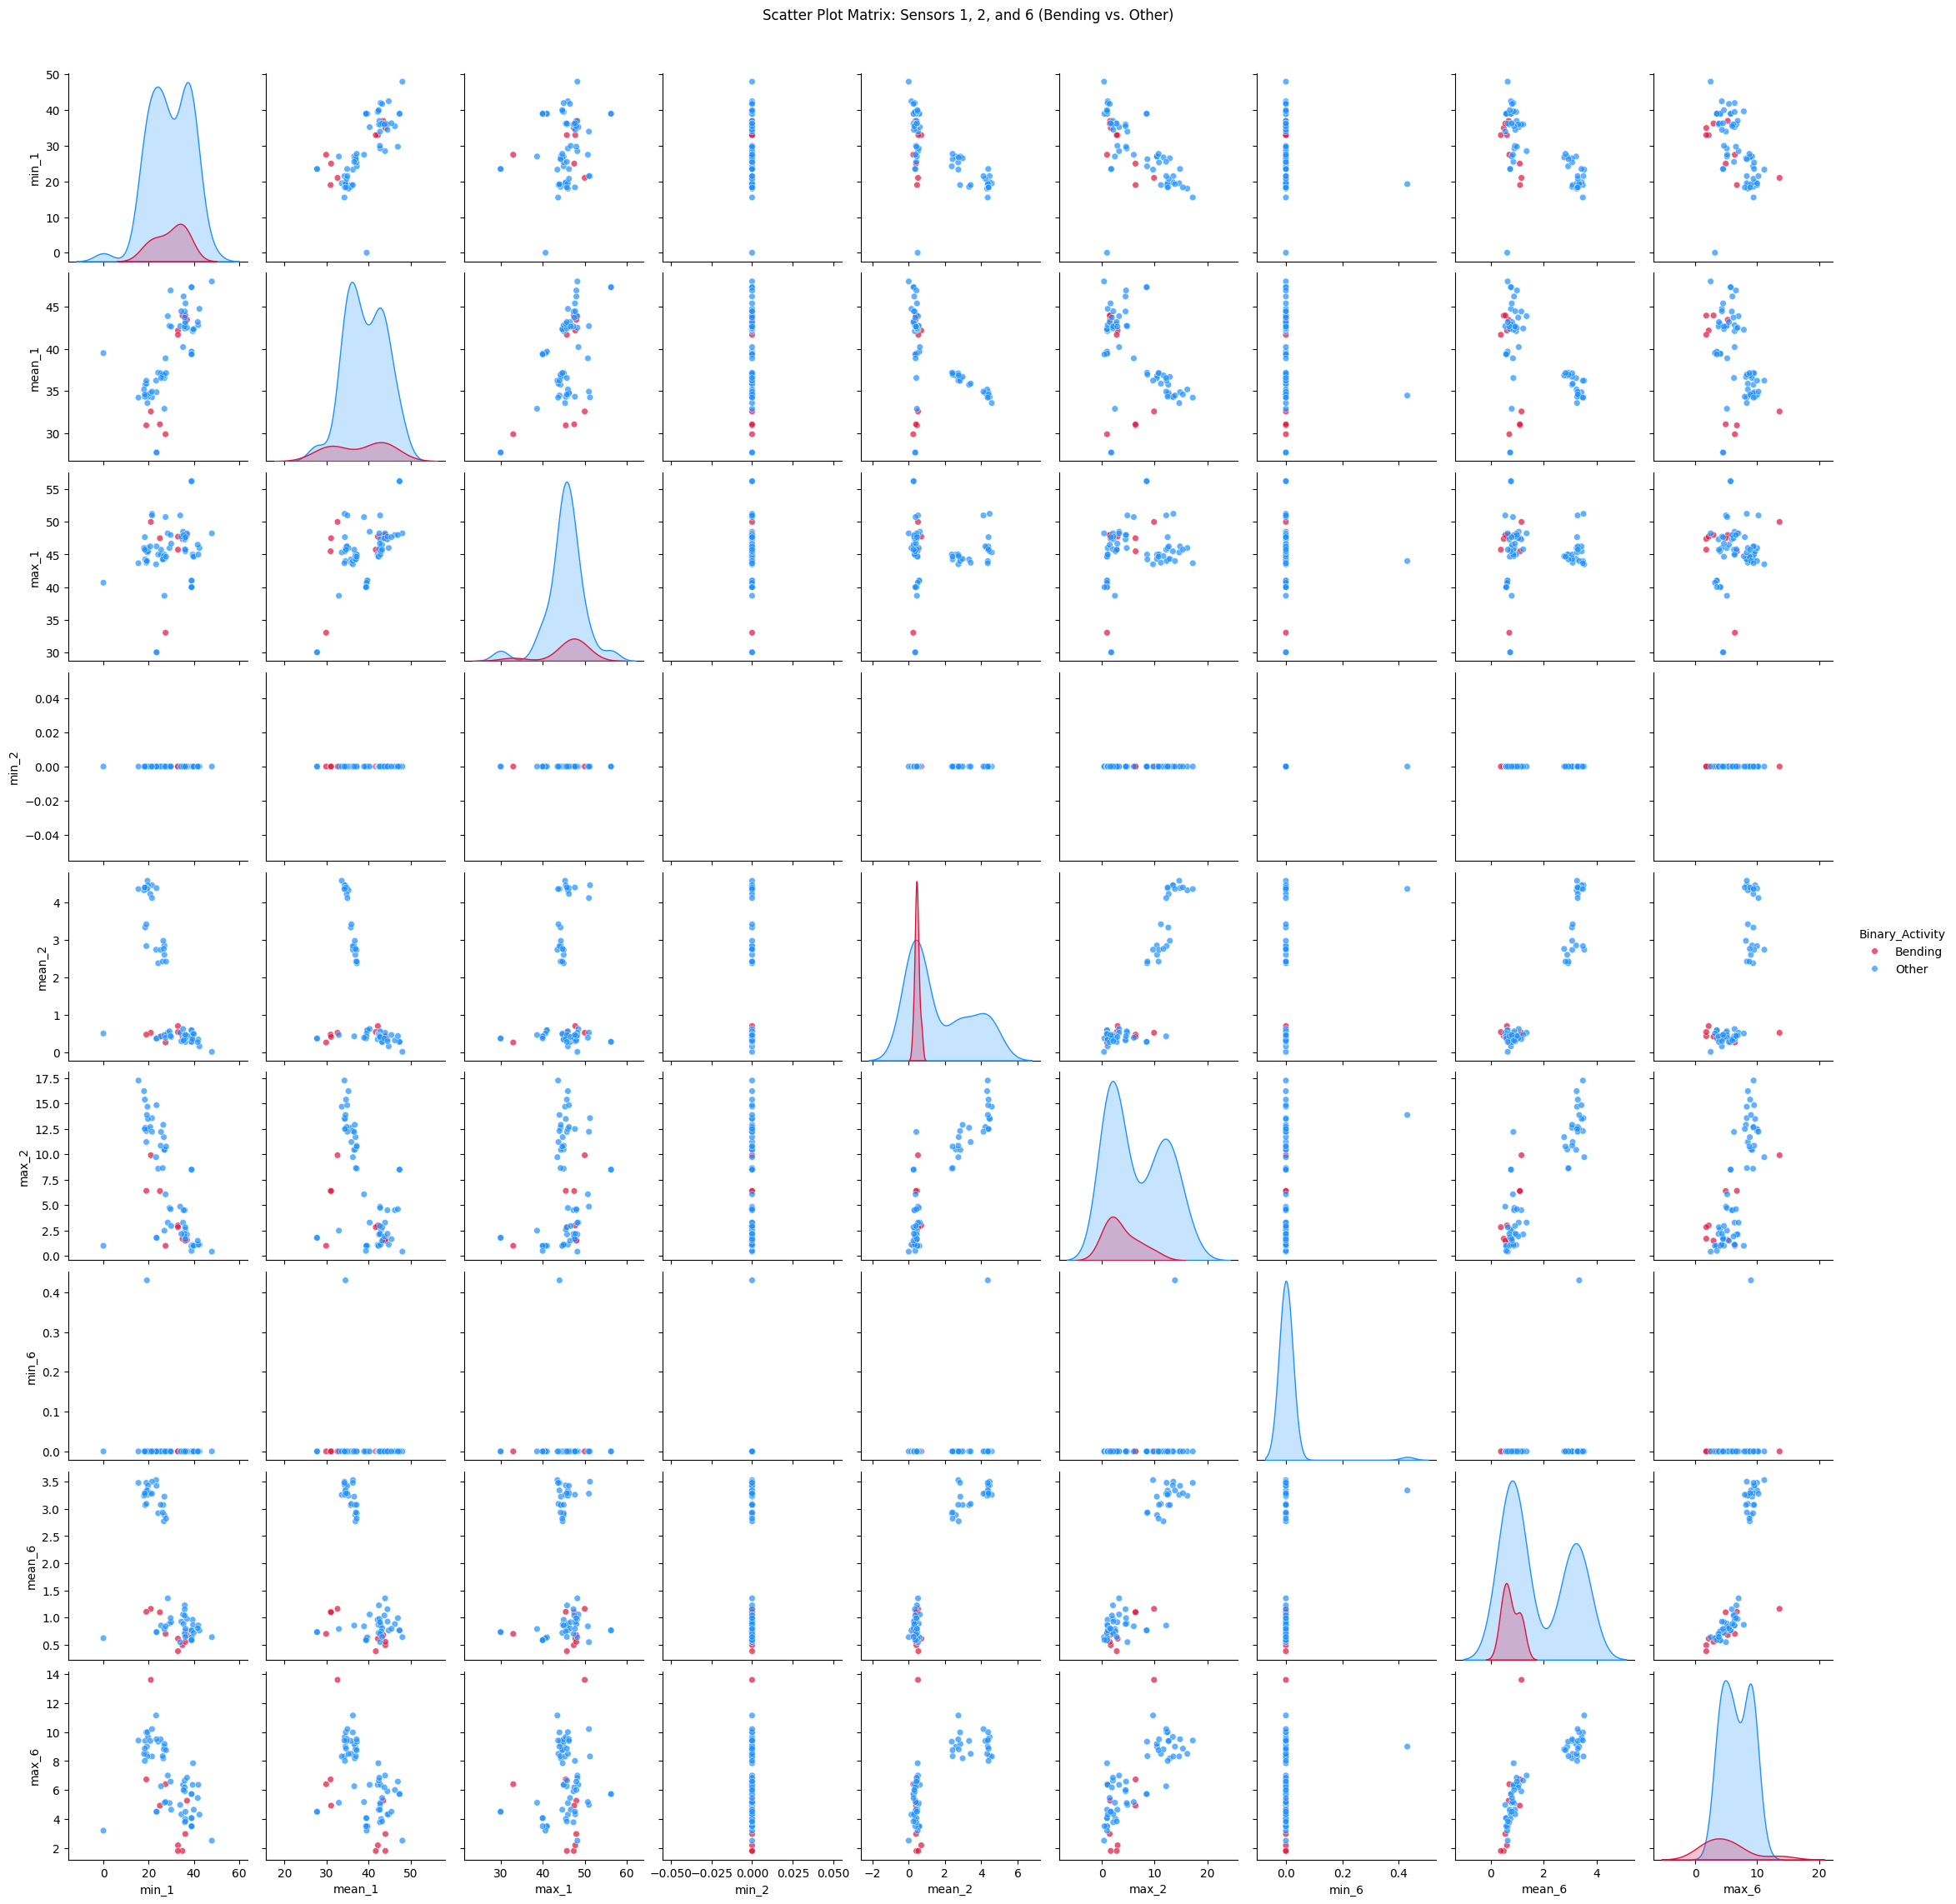

In [50]:
### 2.(a)i. Scatter Plot Matrix for Sensors 1, 2, and 6 ###

# Function to create a binary label for activities: 'Bending' vs 'Other'
def get_binary_activity(activity):
    if 'bending' in str(activity).lower():
        return 'Bending'
    else:
        return 'Other'

# Filter the feature matrix to keep only the training data instances
train_df = feature_matrix[feature_matrix['Split'] == 'train'].copy()

# Create a binary target column: 'Bending' vs 'Other' activities
train_df['Binary_Activity'] = train_df['Activity'].apply(
    get_binary_activity
)

# PLOT 1: Sensors 1, 2, and 6 (Required)
# Select the features: min, mean, and max for time series (sensors) 1, 2, and 6
selected_features = [
    'min_1', 'mean_1', 'max_1',
    'min_2', 'mean_2', 'max_2',
    'min_6', 'mean_6', 'max_6'
]

# Create a subset dataframe containing only those features plus our binary label
plot_df = train_df[selected_features + ['Binary_Activity']]

# Generate the pairwise scatter plots, using color to distinguish classes
sns.pairplot(
    plot_df, 
    hue='Binary_Activity', 
    palette={'Bending': 'crimson', 'Other': 'dodgerblue'}, 
    diag_kind='kde',
    plot_kws={'alpha': 0.7, 's': 30}
)

plt.suptitle("Scatter Plot Matrix: Sensors 1, 2, and 6 (Bending vs. Other)", y=1.02)
plt.show()

#### ii. Splitted Plots

Question 2(a)(i). vs 2(a)(ii). Scatter Plot Analysis

The scatter plots in Question 2(a)(i). vs 2(a)(ii) generally appear similar, with no distinctive improvements after the time series has been split into halves. There is no visual seperation between the bending and other activities even with the additional features. 


Training instances: 69
Number of features: 18
Missing feature values remaining: 0


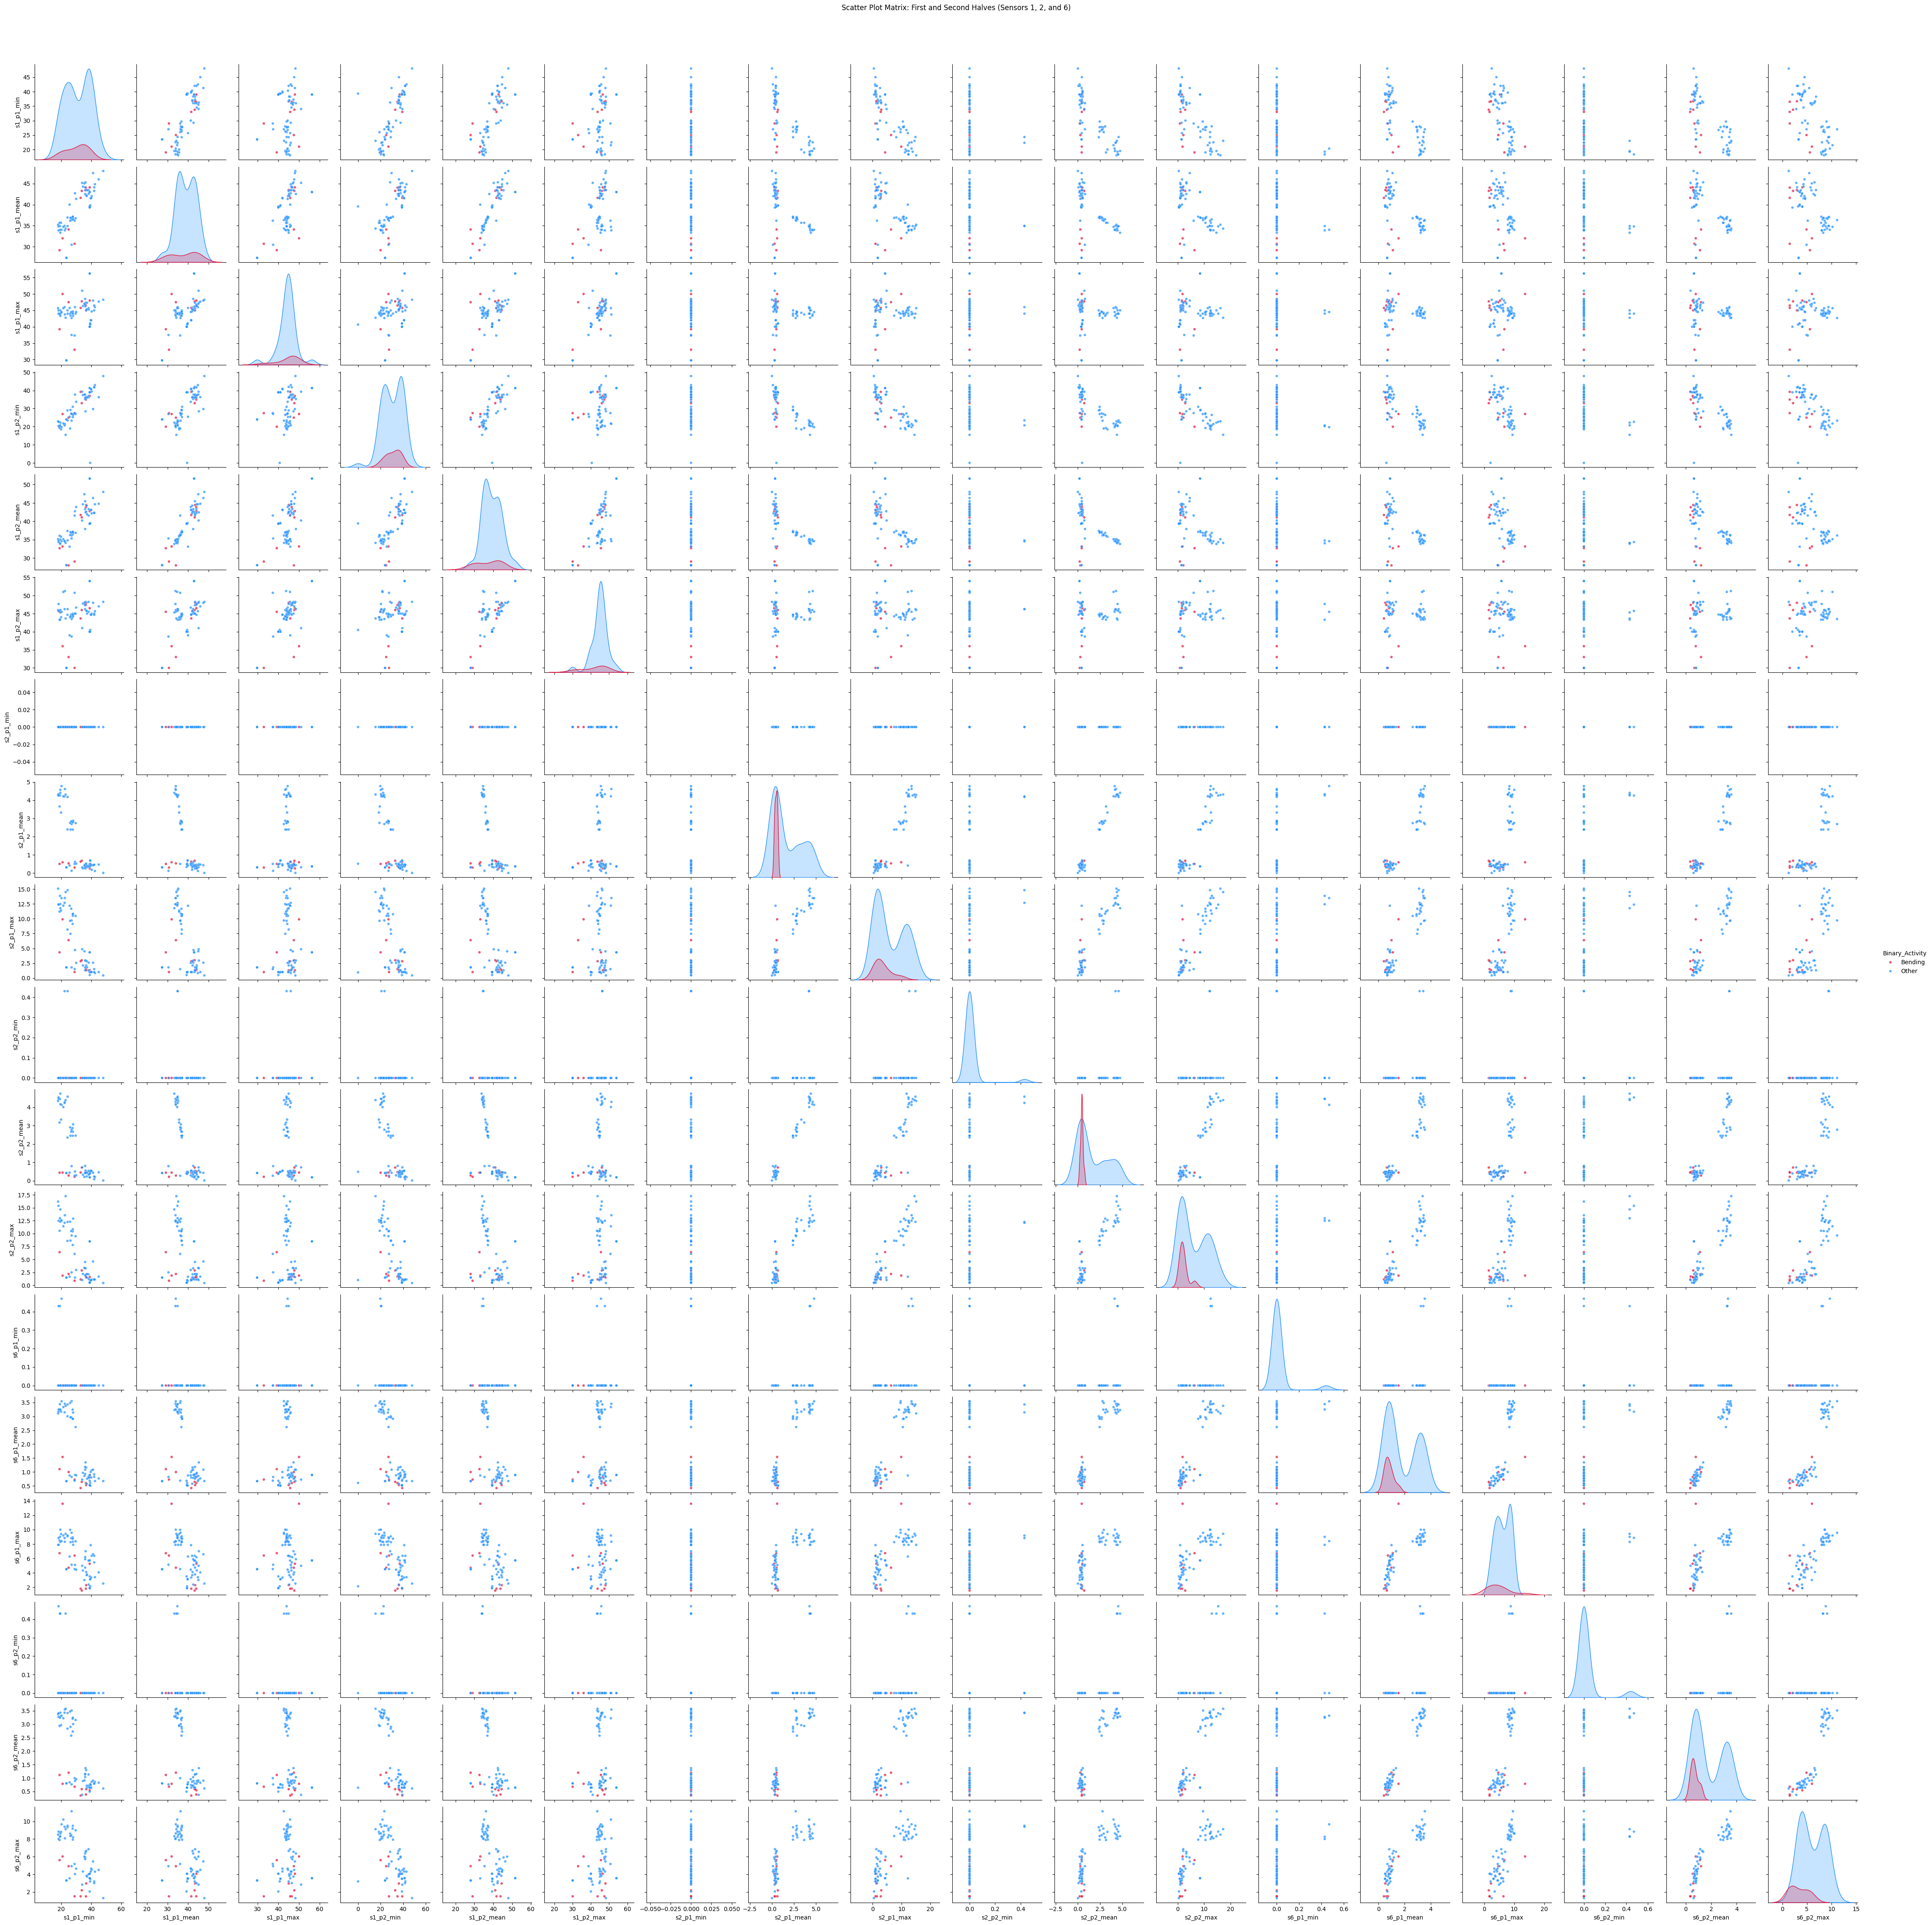

In [51]:
### 2(a)(ii): Split Training Time Series into First and Second Half

split_train_records = []

# Process training instances using the existing file inventory
selected_sensors = {
    1: SENSOR_COLS[0],
    2: SENSOR_COLS[1],
    6: SENSOR_COLS[5]
}

for record in train_files.itertuples(index=False):
    df = load_sensor_data(record.File_Path)

    # Divide each time series into two chronological halves
    mid = len(df) // 2
    parts = {
        'p1': df.iloc[:mid],
        'p2': df.iloc[mid:]
    }

    row_data = {
        'Activity': record.Activity,
        'File_Name': record.File_Name
    }

    # Extract minimum, mean, and maximum for each selected sensor
    for sensor_num, col_name in selected_sensors.items():
        for part_name, part_df in parts.items():
            series = part_df[col_name].dropna()

            row_data[f's{sensor_num}_{part_name}_min'] = (
                series.min() if not series.empty else np.nan
            )
            row_data[f's{sensor_num}_{part_name}_mean'] = (
                series.mean() if not series.empty else np.nan
            )
            row_data[f's{sensor_num}_{part_name}_max'] = (
                series.max() if not series.empty else np.nan
            )

    split_train_records.append(row_data)

# Create the feature DataFrame
split_train_df = pd.DataFrame(split_train_records)

# Select only the 18 numeric features (exclude metadata)
feat_cols = [
    col for col in split_train_df.columns
    if col.startswith(('s1_', 's2_', 's6_'))
]

# Handle missing feature values using column medians
split_train_df[feat_cols] = split_train_df[feat_cols].fillna(
    split_train_df[feat_cols].median()
)

# Create binary activity labels
split_train_df['Binary_Activity'] = (
    split_train_df['Activity'].apply(get_binary_activity)
)

print("Training instances:", len(split_train_df))
print("Number of features:", len(feat_cols))
print(
    "Missing feature values remaining:",
    split_train_df[feat_cols].isnull().sum().sum()
)

# Plot the scatter plot matrix
sns.pairplot(
    split_train_df[feat_cols + ['Binary_Activity']],
    hue='Binary_Activity',
    palette={'Bending': 'crimson', 'Other': 'dodgerblue'},
    diag_kind='kde',
    plot_kws={'alpha': 0.7, 's': 20}
)

plt.suptitle(
    "Scatter Plot Matrix: First and Second Halves "
    "(Sensors 1, 2, and 6)",
    y=1.02
)
plt.show()

#### iii. Time Series Segments

In [52]:
### 2(a)(iii): Segmented Features, RFE, and 5-Fold Cross-Validation

# ------------------------------------------------------------
# PART 1: Extract features for l = 1, 2, ..., 20
# ------------------------------------------------------------

segmented_datasets = {}

for l in range(1, 21):
    records_for_l = []

    # Each CSV file remains one observation
    for record in train_files.itertuples(index=False):
        df = load_sensor_data(record.File_Path)

        # Split the recording into approximately equal segments
        segments = [
            df.iloc[indices]
            for indices in np.array_split(np.arange(len(df)), l)
        ]

        row = {
            'File_Name': record.File_Name,
            'Activity': record.Activity,
            'Binary_Activity': get_binary_activity(record.Activity)
        }

        # Calculate min, mean, and max for all six sensors
        for sensor_num, col_name in enumerate(SENSOR_COLS, start=1):
            for segment_num, segment_df in enumerate(segments, start=1):
                values = segment_df[col_name].dropna()

                if values.empty:
                    minimum = mean = maximum = np.nan
                else:
                    minimum = values.min()
                    mean = values.mean()
                    maximum = values.max()

                row[f's{sensor_num}_seg{segment_num}_min'] = minimum
                row[f's{sensor_num}_seg{segment_num}_mean'] = mean
                row[f's{sensor_num}_seg{segment_num}_max'] = maximum

        records_for_l.append(row)

    segmented_datasets[l] = pd.DataFrame(records_for_l)

# ------------------------------------------------------------
# PART 2: Check the feature datasets
# ------------------------------------------------------------

print("FEATURE EXTRACTION CHECK")

for l, dataset in segmented_datasets.items():
    feature_cols = [
        col for col in dataset.columns if col.startswith('s')
    ]

    assert len(dataset) == len(train_files), (
        f"Unexpected number of observations for l={l}"
    )
    assert len(feature_cols) == 18 * l, (
        f"Unexpected number of features for l={l}"
    )

print(f"Training observations: {len(train_files)}")
print("Expected feature count: 18*l")
print("All row-count and feature-count checks passed.")

# Check missing values before imputation
example_features = [
    col for col in segmented_datasets[2].columns
    if col.startswith('s')
]
print(
    "Missing feature values for l=2:",
    segmented_datasets[2][example_features].isna().sum().sum()
)
# ------------------------------------------------------------
# PART 3: Set up stratified 5-fold cross-validation
# ------------------------------------------------------------

cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)
# ------------------------------------------------------------
# PART 4: Search for the best (l, p) using RFE + logistic regression
# ------------------------------------------------------------

# Candidate numbers of features to retain
# The full-feature model is also tested for each l
p_candidates = [
    5, 10, 15, 20, 25, 30, 40, 50,
    75, 100, 150, 200, 250, 300
]

results = []

for l, dataset in segmented_datasets.items():
    feature_cols = [
        col for col in dataset.columns if col.startswith('s')
    ]

    X = dataset[feature_cols]
    y = dataset['Binary_Activity']

    # Only test p values that do not exceed the available features
    p_values = sorted(set(
        [p for p in p_candidates if p <= len(feature_cols)]
        + [len(feature_cols)]
    ))

    for p in p_values:
        # Fit imputation, scaling, RFE, and classification 
        pipeline = Pipeline([
            ('imputer', SimpleImputer(strategy='median')),
            ('scaler', StandardScaler()),
            ('rfe', RFE(
                estimator=LogisticRegression(max_iter=5000),
                n_features_to_select=p,
                step=0.2
            )),
            ('classifier', LogisticRegression(max_iter=5000))
        ])

        scores = cross_val_score(
            pipeline,
            X,
            y,
            cv=cv,
            scoring='balanced_accuracy'
        )

        results.append({
            'l': l,
            'p': p,
            'Mean_Balanced_Accuracy': scores.mean(),
            'Std_Balanced_Accuracy': scores.std()
        })
# ------------------------------------------------------------
# PART 5: Rank the results and report the best cross-validation classification performance
# ------------------------------------------------------------

# Rank all tested combinations by mean cross-validation score
results_df = pd.DataFrame(results).sort_values(
    'Mean_Balanced_Accuracy',
    ascending=False
).reset_index(drop=True)

print("\nTop 10 combinations:")
print(
    results_df.head(10).to_string(
        index=False,
        float_format=lambda x: f"{x:.4f}"
    )
)

best_result = results_df.iloc[0]

print("\nBest combination among those tested:")
print(f"l = {int(best_result['l'])}")
print(f"p = {int(best_result['p'])}")
print(
    f"Mean balanced accuracy = "
    f"{best_result['Mean_Balanced_Accuracy']:.4f}"
)
print(
    f"Standard deviation = "
    f"{best_result['Std_Balanced_Accuracy']:.4f}"
)

FEATURE EXTRACTION CHECK
Training observations: 69
Expected feature count: 18*l
All row-count and feature-count checks passed.
Missing feature values for l=2: 0

Top 10 combinations:
 l   p  Mean_Balanced_Accuracy  Std_Balanced_Accuracy
 7  15                  0.9500                 0.1000
13  20                  0.9417                 0.0972
19  25                  0.9417                 0.0972
19  50                  0.8917                 0.1167
18  50                  0.8917                 0.1167
18  75                  0.8917                 0.1167
18 100                  0.8917                 0.1167
 8  15                  0.8917                 0.1167
16  25                  0.8917                 0.1167
 6  20                  0.8917                 0.1167

Best combination among those tested:
l = 7
p = 15
Mean balanced accuracy = 0.9500
Standard deviation = 0.1000


#### iv. Confusion Matrix

Training observations: 69
Available predictor features: 126

Selected features:
['s1_seg4_max', 's1_seg5_mean', 's1_seg5_max', 's3_seg5_min', 's3_seg7_min', 's5_seg1_min', 's5_seg1_mean', 's5_seg1_max', 's5_seg2_min', 's5_seg2_mean', 's5_seg2_max', 's5_seg6_min', 's5_seg7_min', 's5_seg7_mean', 's6_seg7_max']

Confusion Matrix (rows=actual, columns=predicted)
Class order: Other (0), Bending (1)
[[60  0]
 [ 0  9]]


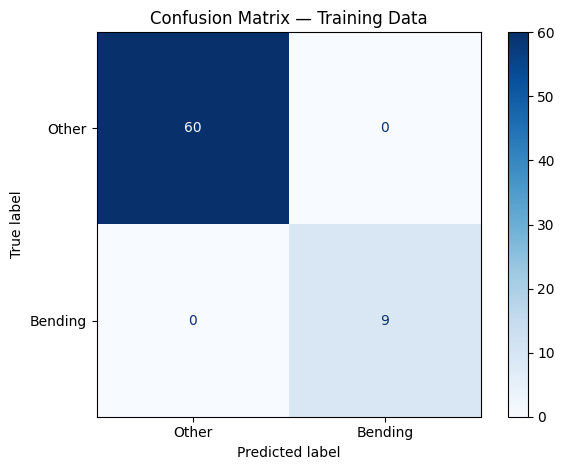

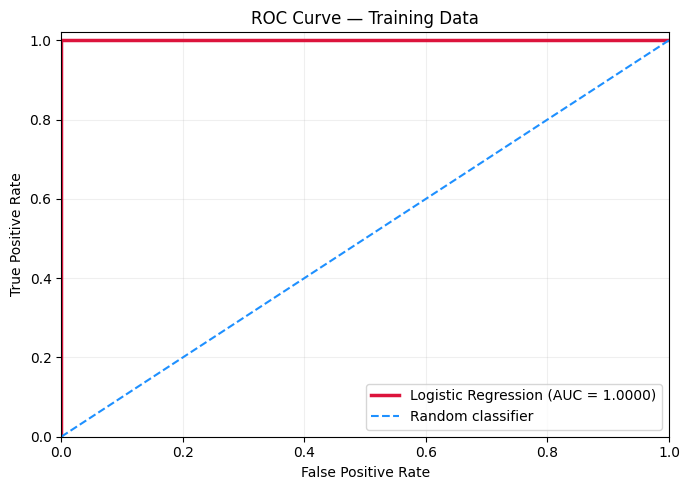

Training AUC: 1.0000

Coefficients and p-values:


,Coefficient (beta),P-value
const,-36.748239,0.999987
s1_seg4_max,1.018033,1.000000
s1_seg5_mean,-12.599775,0.999999
s1_seg5_max,2.196551,1.000000
s3_seg5_min,2.744568,1.000000
s3_seg7_min,-9.903200,0.999999
s5_seg1_min,6.631121,1.000000
s5_seg1_mean,-9.165803,1.000000
s5_seg1_max,19.733690,1.000000
s5_seg2_min,4.172033,1.000000



NOTES: model did not converge. Do not interpret the coefficients or p-values.

NOTES:: Perfect separation was detected. The coefficients and p-values may be unreliable.


In [54]:
### 2(a)(iv): Confusion Matrix, ROC/AUC, Coefficients and P-values

# Use the best combination from 2(a)(iii): l=7, p=15
train_df = segmented_datasets[7].copy()

# Keep training rows if a Split column is present
if 'Split' in train_df.columns:
    train_df = train_df[train_df['Split'] == 'train'].copy()

# Create binary target: Bending=1, Other=0
y_train = (
    train_df['Activity'].apply(get_binary_activity) == 'Bending'
).astype(int)

# Keep numeric predictors and exclude metadata/target columns
metadata_cols = [
    'Instance', 'File_Name', 'File_Path',
    'Activity', 'Split', 'Binary_Activity'
]

X_train = train_df.drop(
    columns=metadata_cols, errors='ignore'
).select_dtypes(include=np.number)

print("Training observations:", len(X_train))
print("Available predictor features:", X_train.shape[1])

# Fit the classifier with RFE selecting 15 features
model = Pipeline([
    ('imputer', SimpleImputer(strategy='median')),
    ('scaler', StandardScaler()),
    ('rfe', RFE(
        estimator=LogisticRegression(max_iter=5000),
        n_features_to_select=15,
        step=0.2
    )),
    ('classifier', LogisticRegression(max_iter=5000))
])

model.fit(X_train, y_train)

# Identify the selected feature names
selected_mask = model.named_steps['rfe'].get_support()
selected_features = X_train.columns[selected_mask].tolist()

print("\nSelected features:")
print(selected_features)

# Predictions on training data
y_pred = model.predict(X_train)
y_prob = model.predict_proba(X_train)[:, 1]

# Confusion matrix
cm = confusion_matrix(y_train, y_pred, labels=[0, 1])

print("\nConfusion Matrix (rows=actual, columns=predicted)")
print("Class order: Other (0), Bending (1)")
print(cm)

# Plot confusion matrix using shades of blue
ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=['Other', 'Bending']
).plot(
    cmap='Blues',
    values_format='d',
    colorbar=True
)

plt.title("Confusion Matrix — Training Data")
plt.tight_layout()
plt.show()

fpr, tpr, _ = roc_curve(y_train, y_prob)
auc = roc_auc_score(y_train, y_prob)

# ROC curve and AUC
plt.figure(figsize=(7, 5))

plt.plot(
    fpr,
    tpr,
    color='crimson',
    linewidth=2.5,
    label=f'Logistic Regression (AUC = {auc:.4f})'
)

plt.plot(
    [0, 1],
    [0, 1],
    color='dodgerblue',
    linestyle='--',
    linewidth=1.5,
    label='Random classifier'
)

plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('ROC Curve — Training Data')
plt.xlim(0, 1)
plt.ylim(0, 1.02)
plt.legend(loc='lower right')
plt.grid(alpha=0.2)
plt.tight_layout()
plt.show()

print(f"Training AUC: {auc:.4f}")

# Transform predictors using the fitted imputer and scaler
X_imputed = model.named_steps['imputer'].transform(X_train)
X_scaled = model.named_steps['scaler'].transform(X_imputed)
X_selected = model.named_steps['rfe'].transform(X_scaled)

X_sm = pd.DataFrame(
    X_selected,
    columns=selected_features,
    index=X_train.index
)

X_sm = sm.add_constant(X_sm, has_constant='add')

# Fit statsmodels logistic regression and capture warnings
import warnings

with warnings.catch_warnings(record=True) as caught_warnings:
    warnings.simplefilter("always")

    try:
        logit_result = sm.Logit(y_train, X_sm).fit(
            disp=False,
            maxiter=1000
        )

        coefficient_table = pd.DataFrame({
            'Coefficient (beta)': logit_result.params,
            'P-value': logit_result.pvalues
        })

        print("\nCoefficients and p-values:")
        display(coefficient_table.round(6))

        # Check whether the estimates are trustworthy
        if not logit_result.mle_retvals.get('converged', False):
            print(
                "\nNOTES: model did not converge. "
                "Do not interpret the coefficients or p-values."
            )

        if not np.isfinite(logit_result.params).all():
            print(
                "\nNOTES: Some coefficients are not finite. "
                "Do not interpret the coefficient table."
            )

        if any(
            'PerfectSeparationWarning' in str(w.category)
            or 'perfect separation' in str(w.message).lower()
            for w in caught_warnings
        ):
            print(
                "\nNOTES:: Perfect separation was detected. "
                "The coefficients and p-values may be unreliable."
            )

    except Exception as e:
        print("\nStatsmodels could not reliably estimate the coefficients.")
        print("Reason:", e)

#### v. Test Classifier

Test recordings: 19
Test predictor features: 126
Expected features: 126

Test Accuracy: 0.9474
Test Balanced Accuracy: 0.8750

Test Confusion Matrix
Class order: Other (0), Bending (1)
[[15  0]
 [ 1  3]]


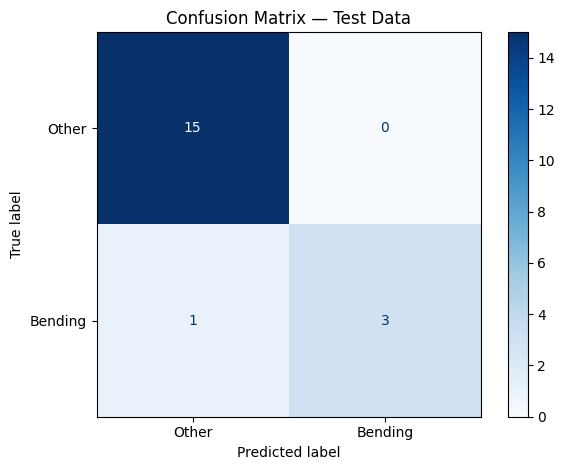


Comparison with Part (iii)
CV Mean Balanced Accuracy: 0.9500
Test Balanced Accuracy:    0.8750
Difference (test - CV):    -0.0750


In [ ]:
### 2(a)(v): Test the classifier on the test set

# Extract features from the original test recordings using l=7
l = 7
test_rows = []

for record in test_files.itertuples(index=False):
    # Load the raw sensor data for this test recording
    sensor_data = load_sensor_data(record.File_Path)

    # Divide the recording into the same 7 segments as training
    segments = [
    sensor_data.iloc[idx]
    for idx in np.array_split(np.arange(len(sensor_data)), l)
    ]

    row = {
        'File_Name': record.File_Name,
        'Activity': record.Activity,
        'Binary_Activity': get_binary_activity(record.Activity)
    }

    # Extract min, mean, and max for each sensor in each segment
    for sensor_num, sensor in enumerate(SENSOR_COLS, start=1):
        for segment_num, segment in enumerate(segments, start=1):
            values = segment[sensor]

            row[f's{sensor_num}_seg{segment_num}_min'] = values.min()
            row[f's{sensor_num}_seg{segment_num}_mean'] = values.mean()
            row[f's{sensor_num}_seg{segment_num}_max'] = values.max()

    test_rows.append(row)

test_df = pd.DataFrame(test_rows)

# Prepare test predictors and labels
y_test = (
    test_df['Binary_Activity'] == 'Bending'
).astype(int)

metadata_cols = ['File_Name', 'Activity', 'Binary_Activity']

X_test = test_df.drop(columns=metadata_cols)

# Match the training feature order exactly
X_test = X_test[X_train.columns]

print("Test recordings:", len(X_test))
print("Test predictor features:", X_test.shape[1])
print("Expected features:", X_train.shape[1])

# Predict using the model already fitted on training data
y_test_pred = model.predict(X_test)

# Calculate test accuracy
test_accuracy = accuracy_score(y_test, y_test_pred)
test_balanced_accuracy = balanced_accuracy_score(
    y_test, y_test_pred
)

print(f"\nTest Accuracy: {test_accuracy:.4f}")
print(f"Test Balanced Accuracy: {test_balanced_accuracy:.4f}")

# Display the test confusion matrix
cm_test = confusion_matrix(y_test, y_test_pred, labels=[0, 1])

print("\nTest Confusion Matrix")
print("Class order: Other (0), Bending (1)")
print(cm_test)

ConfusionMatrixDisplay(
    confusion_matrix=cm_test,
    display_labels=['Other', 'Bending']
).plot(cmap='Blues', values_format='d', colorbar=True)

plt.title("Confusion Matrix — Test Data")
plt.tight_layout()
plt.show()

# Compare test balanced accuracy with 2(a)(iii) cross-validation
cv_balanced_accuracy = 0.9500

print("\nComparison with Part (iii)")
print(f"CV Mean Balanced Accuracy: {cv_balanced_accuracy:.4f}")
print(f"Test Balanced Accuracy:    {test_balanced_accuracy:.4f}")
print(
    "Difference (test - CV):    "
    f"{test_balanced_accuracy - cv_balanced_accuracy:+.4f}"
)

#### vi. Separation Analysis

The classess (Bending and Other) appear to be well seperated in the taining data. The logistic regression classifier resultsed in a test accuracy of 94/74% and a balanced accuracy of 87.50% There are 15 Other recordings in the confusion matrix. CV Mean Balanced Accuracy is 95.00%, while the Test Balanced Accuracy is 87.50% which shows the training data does not secure a strong perfromance on the test data. 

#### vii. Imbalance

Original training class counts:
Other (0): 60
Bending (1): 9

Balanced training sample:
Other (0): 9
Bending (1): 9

Original Bending prevalence: 0.1304
Intercept adjustment: -1.8971
Adjusted intercept: [-1.64521083]

Adjusted Model Confusion Matrix
Rows = actual; columns = predicted
Class order: Other (0), Bending (1)
[[15  0]
 [ 1  3]]


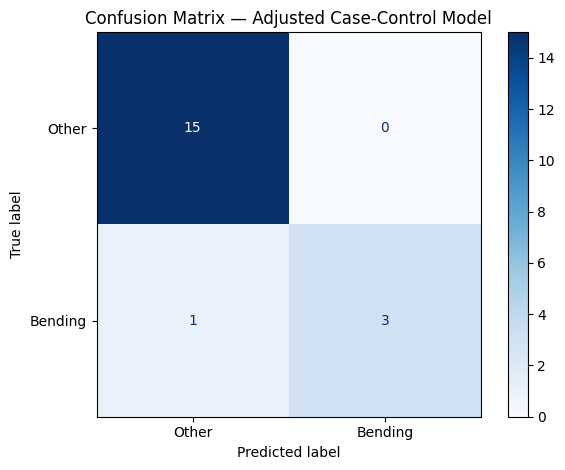

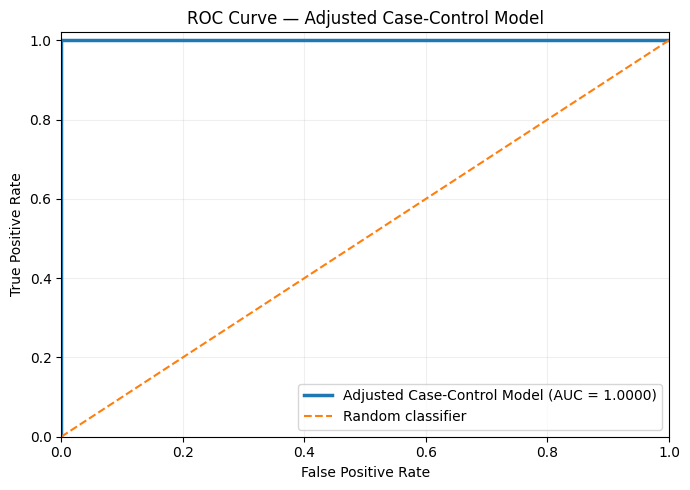

Test AUC (adjusted case-control model): 1.0000


In [ ]:
### 2(a)(vii): Case-control sampling and adjusted logistic regression

# Check class balance in the original training data
n_other = int((y_train == 0).sum())
n_bending = int((y_train == 1).sum())

print("Original training class counts:")
print("Other (0):", n_other)
print("Bending (1):", n_bending)

# Case-control sampling: Other to match Bending
other_indices = y_train[y_train == 0].sample(
    n=n_bending,
    random_state=42
).index

bending_indices = y_train[y_train == 1].index
case_indices = other_indices.union(bending_indices)

X_case = X_train.loc[case_indices]
y_case = y_train.loc[case_indices]

print("\nBalanced training sample:")
print("Other (0):", int((y_case == 0).sum()))
print("Bending (1):", int((y_case == 1).sum()))

# Fit logistic regression using the balanced sample
case_control_model = Pipeline([
    ('imputer', SimpleImputer(strategy='median')),
    ('scaler', StandardScaler()),
    ('rfe', RFE(
        estimator=LogisticRegression(max_iter=5000),
        n_features_to_select=15,
        step=0.2
    )),
    ('classifier', LogisticRegression(max_iter=5000))
])

case_control_model.fit(X_case, y_case)

# Adjust the intercept for the original class proportions
# Balanced sample has equal class proportions
# Correct the intercept to reflect the original training prevalence
original_prevalence = n_bending / (n_other + n_bending)

intercept_adjustment = np.log(
    original_prevalence / (1 - original_prevalence)
)

case_control_model.named_steps['classifier'].intercept_ += (
    intercept_adjustment
)

print("\nOriginal Bending prevalence:", round(original_prevalence, 4))
print("Intercept adjustment:", round(intercept_adjustment, 4))
print("Adjusted intercept:",
      case_control_model.named_steps['classifier'].intercept_)

# Predict on the original test set
y_test_prob = case_control_model.predict_proba(X_test)[:, 1]
y_test_pred = case_control_model.predict(X_test)

# Report the confusion matrix
cm_case = confusion_matrix(y_test, y_test_pred, labels=[0, 1])

print("\nAdjusted Model Confusion Matrix")
print("Rows = actual; columns = predicted")
print("Class order: Other (0), Bending (1)")
print(cm_case)

ConfusionMatrixDisplay(
    confusion_matrix=cm_case,
    display_labels=['Other', 'Bending']
).plot(cmap='Blues', values_format='d')

plt.title("Confusion Matrix — Adjusted Case-Control Model")
plt.tight_layout()
plt.show()

# ROC curve and AUC
fpr_case, tpr_case, _ = roc_curve(y_test, y_test_prob)
auc_case = roc_auc_score(y_test, y_test_prob)

plt.figure(figsize=(7, 5))
plt.plot(
    fpr_case, tpr_case,
    linewidth=2.5,
    label=f'Adjusted Case-Control Model (AUC = {auc_case:.4f})'
)
plt.plot(
    [0, 1], [0, 1],
    linestyle='--',
    label='Random classifier'
)
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('ROC Curve — Adjusted Case-Control Model')
plt.xlim(0, 1)
plt.ylim(0, 1.02)
plt.legend(loc='lower right')
plt.grid(alpha=0.2)
plt.tight_layout()
plt.show()

print(f"Test AUC (adjusted case-control model): {auc_case:.4f}")

2(a)vii. Imbalance Written Analysis

The training classes are imbalanced with 60 Other and 9 Bending recordings. Case-control sampling was used to balance the training with the logistic regression adjusted. 

### (b) Binary Classification Using L1-penalized logistic regression

#### i. Time Series Segments

In [ ]:

### 2(b)(i): L1-penalized logistic regression with cross-validation

# Define cross-validation and candidate C values
cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

C_values = [0.001, 0.01, 0.1, 1, 10, 100, 1000]

results_l1 = []

# Test each number of segments, l = 1 to 20
for l in range(1, 21):

    df = segmented_datasets[l].copy()

    # Create binary target: Bending=1, Other=0
    y = (
        df['Activity'].apply(get_binary_activity) == 'Bending'
    ).astype(int)

    # Keep numeric predictor features and exclude metadata
    metadata_cols = [
        'Instance', 'File_Name', 'File_Path',
        'Activity', 'Split', 'Binary_Activity'
    ]

    X = df.drop(
        columns=metadata_cols,
        errors='ignore'
    ).select_dtypes(include=np.number)

    # Build L1-penalized logistic regression pipeline
    pipeline = Pipeline([
        ('imputer', SimpleImputer(strategy='median')),
        ('scaler', StandardScaler()),
        ('classifier', LogisticRegression(
            l1_ratio=1.0,
            solver='liblinear',
            max_iter=10000,
            random_state=42
        ))
    ])

    # Cross-validate C for this value of l
    search = GridSearchCV(
        estimator=pipeline,
        param_grid={'classifier__C': C_values},
        scoring='balanced_accuracy',
        cv=cv,
        n_jobs=-1,
        refit=True
    )

    search.fit(X, y)

    # Count nonzero coefficients in the best model
    coefficients = (
        search.best_estimator_
        .named_steps['classifier'].coef_[0]
    )

    selected_count = int(
        np.sum(np.abs(coefficients) > 1e-8)
    )

    results_l1.append({
        'l': l,
        'Feature_Count': X.shape[1],
        'Best_C': search.best_params_['classifier__C'],
        'Selected_Features': selected_count,
        'Mean_Balanced_Accuracy': search.best_score_,
        'Std_Balanced_Accuracy': search.cv_results_[
            'std_test_score'
        ][search.best_index_]
    })

# Compare results across all values of l
l1_results_df = pd.DataFrame(results_l1)

l1_results_df = l1_results_df.sort_values(
    'Mean_Balanced_Accuracy',
    ascending=False
).reset_index(drop=True)

print("Top 10 L1 logistic regression combinations:")
display(l1_results_df.head(10).round(4))

# Report the best combination
best_l1_result = l1_results_df.iloc[0]

print("\nBest L1 logistic regression combination:")
print("l =", int(best_l1_result['l']))
print("C =", best_l1_result['Best_C'])
print(
    "Selected features =",
    int(best_l1_result['Selected_Features'])
)
print(
    "Mean CV balanced accuracy =",
    round(best_l1_result['Mean_Balanced_Accuracy'], 4)
)
print(
    "Standard deviation =",
    round(best_l1_result['Std_Balanced_Accuracy'], 4)
)

Top 10 L1 logistic regression combinations:


,l,Feature_Count,Best_C,Selected_Features,Mean_Balanced_Accuracy,Std_Balanced_Accuracy
0,1,18,100,10,1.0000,0.0000
1,7,126,1000,41,0.9417,0.0972
2,12,216,10,8,0.9417,0.0972
3,2,36,10,10,0.9417,0.0972
4,11,198,10,12,0.9417,0.0972
5,20,360,100,24,0.9417,0.0972
6,6,108,1000,29,0.9333,0.0935
7,10,180,100,18,0.8917,0.1167
8,13,234,1,8,0.8917,0.1167
9,14,252,1,10,0.8917,0.1167



Best L1 logistic regression combination:
l = 1
C = 100.0
Selected features = 10
Mean CV balanced accuracy = 1.0
Standard deviation = 0.0


#### ii. Comparison

In [ ]:
# 2(b)(ii): Compare p-value-based selection and L1 regularization

comparison_df = pd.DataFrame({
    'Method': [
        'P-value variable selection',
        'L1-penalized logistic regression'
    ],
    'Best l': [7, 1],
    'Mean CV Balanced Accuracy': [0.9500, 1.0000],
    'Std CV Balanced Accuracy': [0.1000, 0.0000]
})

display(comparison_df)

,Method,Best l,Mean CV Balanced Accuracy,Std CV Balanced Accuracy
0,P-value variable selection,7,0.95,0.1
1,L1-penalized logistic regression,1,1.00,0.0


Based on the results of in L1-penialized logistic regression (Std CV Balanced Accuracy = 0.00), it appears to have performed well compared to P-value variable selection (Std CV Balanced Accuracy = 0.1). These results demonstrate the performance of the five folds, a smaller standard deviation value displays no variation was detected in the model's balanced accuracy. In the P-value variable selection, its standard deviation value indicates there were variations in across the five folds. According to the Mean CV Balanced Accuracy, L1-penialized showed more accurate results than P-value of 100% compared to 95%. 

### (c) Multi-class Classification (The Realistic Case)

#### i. Time Series Segments

In [ ]:
# 2(c)(i): Multiclass L1-penalized logistic regression
# PART 1: Set up cross-validation and candidate C values

C_values = [0.001, 0.01, 0.1, 1, 10, 100, 1000]

# Find the smallest number of training recordings in any activity class.
first_df = segmented_datasets[1]
class_counts = first_df['Activity'].value_counts()
n_splits = min(5, int(class_counts.min()))

print("Training recordings per activity:")
print(class_counts)
print(f"\nUsing {n_splits}-fold stratified cross-validation.")

cv = StratifiedKFold(n_splits=n_splits, shuffle=True, random_state=42)

results_multiclass = []
best_cv_score = -1
best_l = None
best_C = None
best_model = None

metadata_cols = [
    'Instance', 'File_Name', 'File_Path',
    'Activity', 'Split', 'Binary_Activity'
]

for l in range(1, 21):
    df = segmented_datasets[l].copy()

    # Keep the original activity names as the multiclass target.
    y = df['Activity'].astype(str)

    # Use only numeric sensor features.
    X = (
        df.drop(columns=metadata_cols, errors='ignore')
          .select_dtypes(include=np.number)
    )

    pipeline = Pipeline([
        ('imputer', SimpleImputer(strategy='median')),
        ('scaler', StandardScaler()),
        ('classifier', LogisticRegression(
            l1_ratio=1.0,
            solver='saga',
            max_iter=20000,
            random_state=42
        ))
    ])

    search = GridSearchCV(
        estimator=pipeline,
        param_grid={'classifier__C': C_values},
        scoring='balanced_accuracy',
        cv=cv,
        n_jobs=-1,
        refit=True
    )

    search.fit(X, y)

    coefficients = search.best_estimator_.named_steps['classifier'].coef_
    selected_count = int(np.sum(np.any(np.abs(coefficients) > 1e-8, axis=0)))

    results_multiclass.append({
        'l': l,
        'Feature_Count': X.shape[1],
        'Best_C': search.best_params_['classifier__C'],
        'Selected_Features': selected_count,
        'Mean_Balanced_Accuracy': search.best_score_,
        'Std_Balanced_Accuracy':
            search.cv_results_['std_test_score'][search.best_index_]
    })

    if search.best_score_ > best_cv_score:
        best_cv_score = search.best_score_
        best_l = l
        best_C = search.best_params_['classifier__C']
        best_model = search.best_estimator_

multiclass_results_df = (
    pd.DataFrame(results_multiclass)
      .sort_values('Mean_Balanced_Accuracy', ascending=False)
      .reset_index(drop=True)
)

print("\nTop 10 multiclass L1 combinations:")
display(multiclass_results_df.head(10).round(4))

print("\nBest multiclass L1 model:")
print("Number of segments (l):", best_l)
print("Best C:", best_C)
print("Nonzero features:", int(
    np.sum(np.any(np.abs(best_model.named_steps['classifier'].coef_) > 1e-8, axis=0))
))
print("Mean CV balanced accuracy:", round(best_cv_score, 4))
print("CV standard deviation:", round(
    multiclass_results_df.loc[
        multiclass_results_df['l'] == best_l,
        'Std_Balanced_Accuracy'
    ].iloc[0], 4
))

Training recordings per activity:
Activity
cycling     12
lying       12
sitting     12
standing    12
walking     12
bending1     5
bending2     4
Name: count, dtype: int64

Using 4-fold stratified cross-validation.

Top 10 multiclass L1 combinations:


,l,Feature_Count,Best_C,Selected_Features,Mean_Balanced_Accuracy,Std_Balanced_Accuracy
0,20,360,1,67,0.8452,0.0704
1,1,18,1,11,0.8393,0.1109
2,6,108,1000,108,0.8095,0.1166
3,8,144,1000,144,0.8095,0.0891
4,9,162,1000,162,0.8036,0.0681
5,18,324,1000,324,0.8036,0.0681
6,7,126,1000,126,0.7976,0.0914
7,17,306,1000,306,0.7917,0.0848
8,11,198,1000,198,0.7798,0.1319
9,15,270,1000,270,0.7798,0.1319



Best multiclass L1 model:
Number of segments (l): 20
Best C: 1
Nonzero features: 67
Mean CV balanced accuracy: 0.8452
CV standard deviation: 0.0704


Best l: 20
Best C: 1
Number of test recordings: 19
Test accuracy: 0.7368
Test error: 0.2632 (26.32%)

Classification report:
              precision    recall  f1-score   support

    bending1       1.00      1.00      1.00         2
    bending2       1.00      0.50      0.67         2
     cycling       0.75      1.00      0.86         3
       lying       1.00      1.00      1.00         3
     sitting       0.40      0.67      0.50         3
    standing       0.50      0.33      0.40         3
     walking       1.00      0.67      0.80         3

    accuracy                           0.74        19
   macro avg       0.81      0.74      0.75        19
weighted avg       0.79      0.74      0.74        19



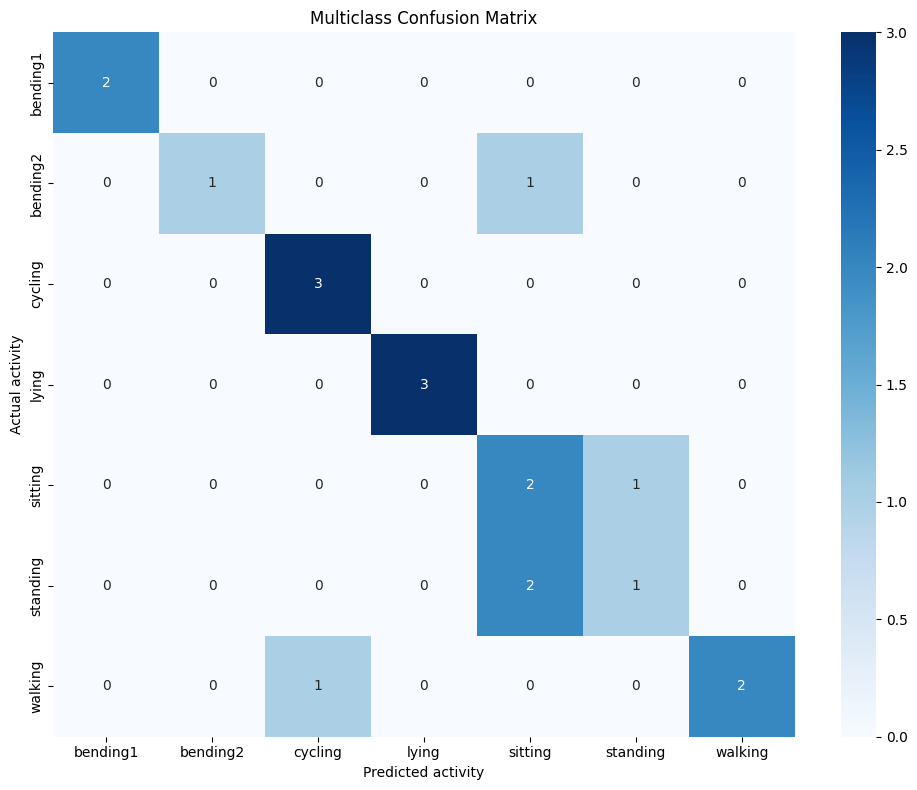

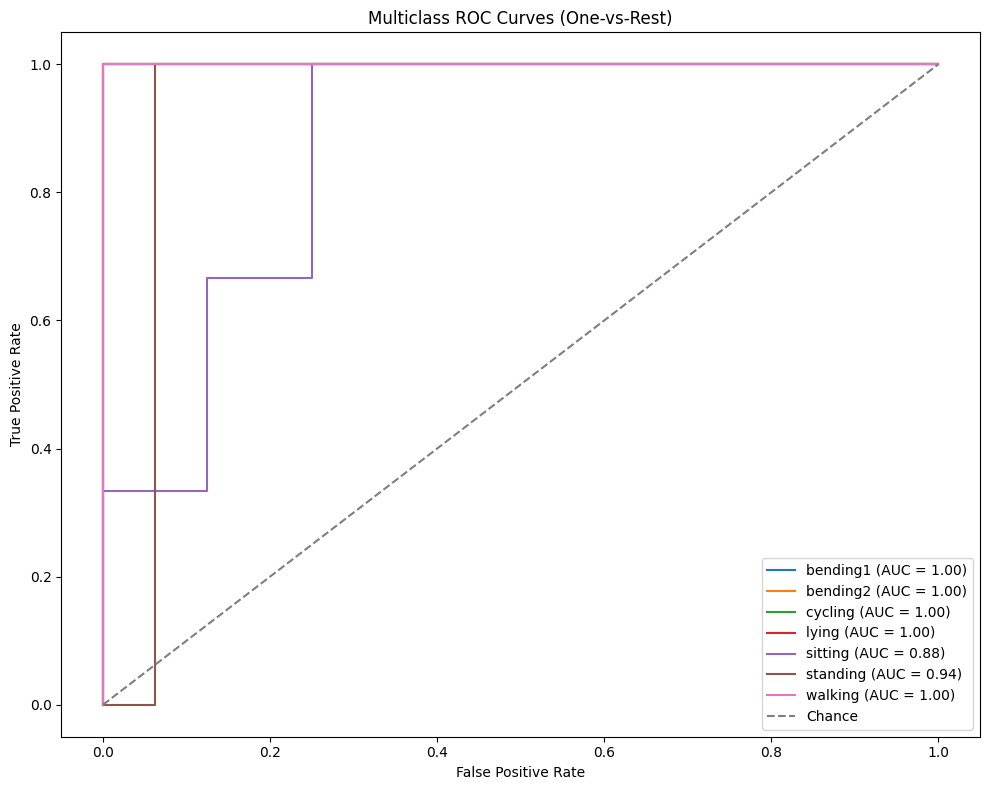

In [ ]:
# 2(c)(i): Build test features using the best number of segments from CV
# PART 2: Extract features from the original test recordings using best_l

test_rows = []

for record in test_files.itertuples(index=False):
    sensor_data = load_sensor_data(record.File_Path)

    segments = [
        sensor_data.iloc[idx]
        for idx in np.array_split(np.arange(len(sensor_data)), best_l)
    ]

    row = {
        'File_Name': record.File_Name,
        'Activity': str(record.Activity)
    }

    for sensor_num, sensor in enumerate(SENSOR_COLS, start=1):
        for segment_num, segment in enumerate(segments, start=1):
            values = segment[sensor]
            row[f's{sensor_num}_seg{segment_num}_min'] = values.min()
            row[f's{sensor_num}_seg{segment_num}_mean'] = values.mean()
            row[f's{sensor_num}_seg{segment_num}_max'] = values.max()

    test_rows.append(row)

test_df_multiclass = pd.DataFrame(test_rows)

# Match the training feature columns and their order.
train_df_best = segmented_datasets[best_l].copy()
X_train_best = (
    train_df_best.drop(columns=metadata_cols, errors='ignore')
                 .select_dtypes(include=np.number)
)
X_test_multiclass = test_df_multiclass.drop(
    columns=['File_Name', 'Activity']
)
X_test_multiclass = X_test_multiclass[X_train_best.columns]

y_test_multiclass = test_df_multiclass['Activity']
y_pred_multiclass = best_model.predict(X_test_multiclass)
y_prob_multiclass = best_model.predict_proba(X_test_multiclass)

# Test error
test_accuracy = accuracy_score(y_test_multiclass, y_pred_multiclass)
test_error = 1 - test_accuracy

print("Best l:", best_l)
print("Best C:", best_C)
print("Number of test recordings:", len(y_test_multiclass))
print(f"Test accuracy: {test_accuracy:.4f}")
print(f"Test error: {test_error:.4f} ({test_error * 100:.2f}%)")

print("\nClassification report:")
print(classification_report(
    y_test_multiclass,
    y_pred_multiclass,
    zero_division=0
))

# Multiclass confusion matrix
classes = best_model.named_steps['classifier'].classes_
cm = confusion_matrix(
    y_test_multiclass,
    y_pred_multiclass,
    labels=classes
)

plt.figure(figsize=(10, 8))
sns.heatmap(
    cm, annot=True, fmt='d', cmap='Blues',
    xticklabels=classes, yticklabels=classes
)
plt.xlabel('Predicted activity')
plt.ylabel('Actual activity')
plt.title('Multiclass Confusion Matrix')
plt.tight_layout()
plt.show()

# Multiclass ROC: one activity vs. all remaining activities
y_test_binary = label_binarize(y_test_multiclass, classes=classes)

plt.figure(figsize=(10, 8))
for i, activity in enumerate(classes):
    # ROC requires both positive and negative examples for this activity.
    if len(np.unique(y_test_binary[:, i])) < 2:
        print(f"Skipping ROC for {activity}: test set lacks a positive or negative example.")
        continue

    fpr, tpr, _ = roc_curve(y_test_binary[:, i], y_prob_multiclass[:, i])
    class_auc = auc(fpr, tpr)

    plt.plot(fpr, tpr, label=f'{activity} (AUC = {class_auc:.2f})')

plt.plot([0, 1], [0, 1], linestyle='--', label='Chance')
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('Multiclass ROC Curves (One-vs-Rest)')
plt.legend(loc='best')
plt.tight_layout()
plt.show()

#### ii. Naive Bayes

In [ ]:
# 2(c)(ii): Gaussian and Multinomial Naïve Bayes
# PART 1: Set up cross-validation and candidate models

metadata_cols = [
    'Instance', 'File_Name', 'File_Path',
    'Activity', 'Split', 'Binary_Activity'
]

# Use the same CV setup as 2(c)(i).
class_counts = segmented_datasets[1]['Activity'].value_counts()
n_splits = min(5, int(class_counts.min()))
cv = StratifiedKFold(n_splits=n_splits, shuffle=True, random_state=42)

nb_results = []
best_nb_models = {}

for model_name, classifier, scaler in [
    ('GaussianNB', GaussianNB(), StandardScaler()),
    ('MultinomialNB', MultinomialNB(), MinMaxScaler())
]:
    for l in range(1, 21):
        df = segmented_datasets[l].copy()
        y = df['Activity'].astype(str)

        X = (
            df.drop(columns=metadata_cols, errors='ignore')
              .select_dtypes(include=np.number)
        )

        pipeline = Pipeline([
            ('imputer', SimpleImputer(strategy='median')),
            ('scaler', scaler),
            ('classifier', classifier)
        ])

        search = GridSearchCV(
            estimator=pipeline,
            param_grid={},
            scoring='balanced_accuracy',
            cv=cv,
            n_jobs=-1,
            refit=True
        )
        search.fit(X, y)

        nb_results.append({
            'Model': model_name,
            'l': l,
            'Mean_CV_Balanced_Accuracy': search.best_score_,
            'Std_CV_Balanced_Accuracy':
                search.cv_results_['std_test_score'][search.best_index_]
        })

        best_nb_models[(model_name, l)] = search.best_estimator_

nb_results_df = pd.DataFrame(nb_results)

print("Best segment count for each Naïve Bayes model:")
display(
    nb_results_df.sort_values(
        'Mean_CV_Balanced_Accuracy', ascending=False
    ).groupby('Model', as_index=False).first().round(4)
)

print("\nAll results:")
display(
    nb_results_df.sort_values(
        ['Model', 'Mean_CV_Balanced_Accuracy'],
        ascending=[True, False]
    ).round(4)
)

Best segment count for each Naïve Bayes model:


,Model,l,Mean_CV_Balanced_Accuracy,Std_CV_Balanced_Accuracy
0,GaussianNB,1,0.8036,0.0722
1,MultinomialNB,1,0.6607,0.1122



All results:


,Model,l,Mean_CV_Balanced_Accuracy,Std_CV_Balanced_Accuracy
0,GaussianNB,1,0.8036,0.0722
1,GaussianNB,2,0.7560,0.0638
8,GaussianNB,9,0.6964,0.1134
6,GaussianNB,7,0.6845,0.1777
2,GaussianNB,3,0.6726,0.0958
3,GaussianNB,4,0.6607,0.0542
4,GaussianNB,5,0.6607,0.0681
7,GaussianNB,8,0.6607,0.1070
5,GaussianNB,6,0.6131,0.1392
9,GaussianNB,10,0.5774,0.0831



GaussianNB
Best l: 1
Test error: 0.1053 (10.53%)

Classification report:
              precision    recall  f1-score   support

    bending1       1.00      1.00      1.00         2
    bending2       1.00      1.00      1.00         2
     cycling       1.00      1.00      1.00         3
       lying       0.67      0.67      0.67         3
     sitting       0.75      1.00      0.86         3
    standing       1.00      0.67      0.80         3
     walking       1.00      1.00      1.00         3

    accuracy                           0.89        19
   macro avg       0.92      0.90      0.90        19
weighted avg       0.91      0.89      0.89        19



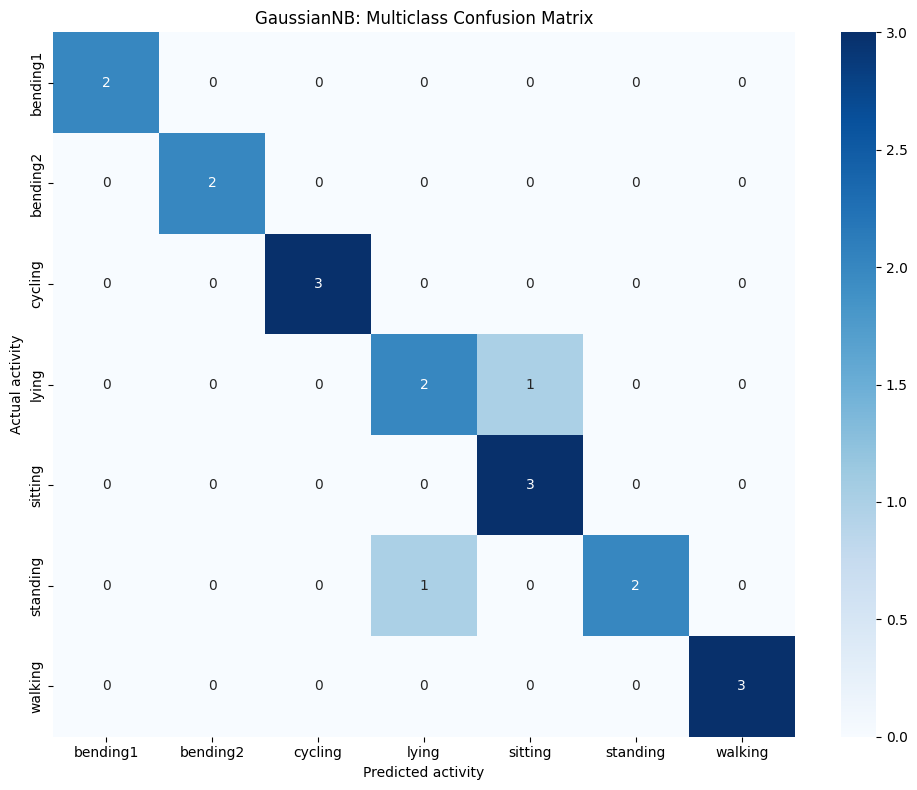


MultinomialNB
Best l: 1
Test error: 0.3158 (31.58%)

Classification report:
              precision    recall  f1-score   support

    bending1       1.00      1.00      1.00         2
    bending2       0.00      0.00      0.00         2
     cycling       0.75      1.00      0.86         3
       lying       0.67      0.67      0.67         3
     sitting       0.40      0.67      0.50         3
    standing       0.50      0.33      0.40         3
     walking       1.00      1.00      1.00         3

    accuracy                           0.68        19
   macro avg       0.62      0.67      0.63        19
weighted avg       0.63      0.68      0.65        19



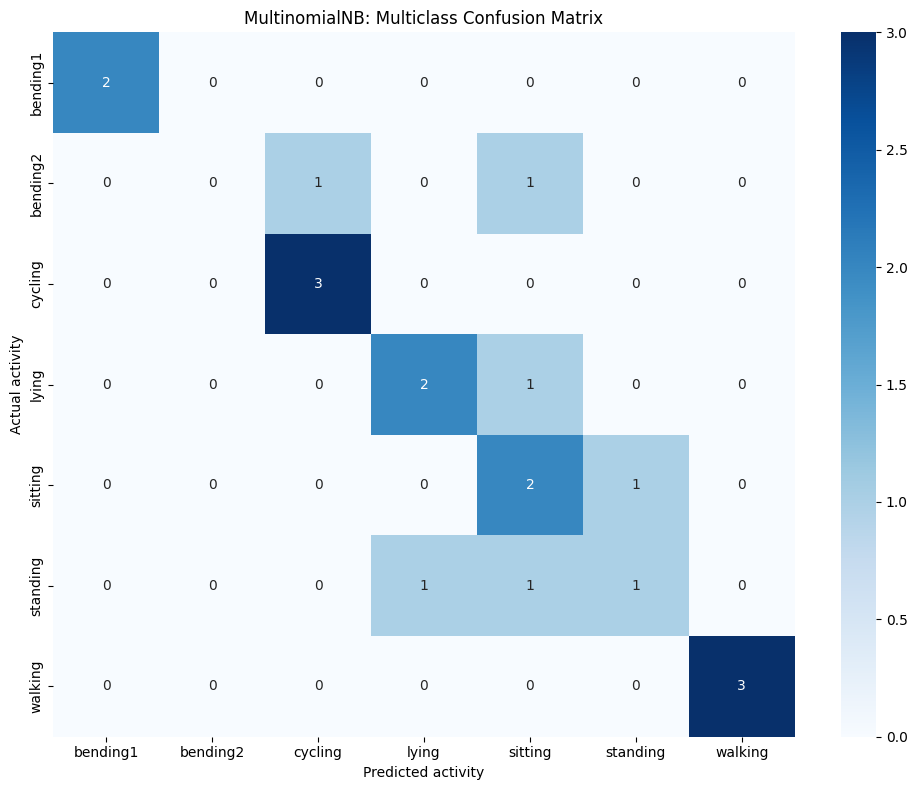

In [ ]:
# 2(c)(ii): Gaussian and Multinomial Naïve Bayes
# PART 2: Test the best Naïve Bayes models on the original test recordings

best_nb_l = (
    nb_results_df.sort_values('Mean_CV_Balanced_Accuracy', ascending=False)
    .groupby('Model', as_index=False)
    .first()
    .set_index('Model')['l']
    .astype(int)
    .to_dict()
)

def build_nb_test_data(l):
    rows = []

    for record in test_files.itertuples(index=False):
        sensor_data = load_sensor_data(record.File_Path)
        segments = [
            sensor_data.iloc[idx]
            for idx in np.array_split(np.arange(len(sensor_data)), l)
        ]

        row = {'Activity': str(record.Activity)}

        for sensor_num, sensor in enumerate(SENSOR_COLS, start=1):
            for segment_num, segment in enumerate(segments, start=1):
                values = segment[sensor]
                row[f's{sensor_num}_seg{segment_num}_min'] = values.min()
                row[f's{sensor_num}_seg{segment_num}_mean'] = values.mean()
                row[f's{sensor_num}_seg{segment_num}_max'] = values.max()

        rows.append(row)

    test_df = pd.DataFrame(rows)
    return test_df.drop(columns='Activity'), test_df['Activity']

nb_test_outputs = {}

for model_name in ['GaussianNB', 'MultinomialNB']:
    l = best_nb_l[model_name]
    model = best_nb_models[(model_name, l)]

    X_train = (
        segmented_datasets[l]
        .drop(columns=metadata_cols, errors='ignore')
        .select_dtypes(include=np.number)
    )
    X_test, y_test = build_nb_test_data(l)
    X_test = X_test[X_train.columns]

    y_pred = model.predict(X_test)
    nb_test_outputs[model_name] = (model, X_test, y_test, y_pred)

    test_error = 1 - accuracy_score(y_test, y_pred)

    print(f"\n{model_name}")
    print("Best l:", l)
    print(f"Test error: {test_error:.4f} ({test_error * 100:.2f}%)")
    print("\nClassification report:")
    print(classification_report(y_test, y_pred, zero_division=0))

    classes = model.named_steps['classifier'].classes_
    cm = confusion_matrix(y_test, y_pred, labels=classes)

    plt.figure(figsize=(10, 8))
    sns.heatmap(
        cm, annot=True, fmt='d', cmap='Blues',
        xticklabels=classes, yticklabels=classes
    )
    plt.xlabel('Predicted activity')
    plt.ylabel('Actual activity')
    plt.title(f'{model_name}: Multiclass Confusion Matrix')
    plt.tight_layout()
    plt.show()

#### ii. Comparison

GaussianNB is the most ideal method based on its lowest test error rates of 10.53%, compared to 26.32% for L1-penalized multinomial regression and 31/58% for Multinomial Naive Bayes. The GaussianNB Multiclass Confusion Matrix displays higher values (marked in dark blue) of correctly classified records on the diagonal, which indicates correct predicitions. There were less classification errors and maintained highest accuracy.

## 3. ISLR 4.8.3

Bayes classifer in a Linear Discriminant Analysis is a straight line since each class has the same variance, making the distributions to drop at identical points. Quadratic Discriminant Analysis (QDA) allows each class to uphold different variances. The curves falling at various and distribution tails crossing at multiple points. This impacts the decision boundary as it curves along each observation, resulting in a quadratic form. 

## 4. ISLR 4.8.7

The likelihood of a four percent profit is under the normal distribution for both groups, the likelihood for non-dividend companies is slightly higher. Combining each group's baseline frequency with its profit likelihood creates a weighted probability that favors issuing a dividend. The final calculated probability that this company will issue a dividend is approximately 0.752 using Bayes Therorem. 

To prove the probability of a company issuing a dividend given a four percent profit is approximately 75.2%, we analyze how baseline class rates interact with normal distribution. Baseline favorability is due to 80% of companies issue dividends, while only 20% do not. This creates a 4 to 1 baseline advantage in favor of issuing a dividend before any profit data. A profit of 4% is 6 units away from the dividend group mean (10%) and 4 units away from the non-dividend group mean (0%). Therefore, a profit of 4% is slightly more common for non-dividend companies than dividend companies. To find the final likelihood, we multiply the baseline odds by the feature likelihoods. The 4 to 1 baseline advantage for issuing a dividend easily dominates the feature preference for not issuing a dividend. Combining a relative share of about 3 to 1 (dividend to no dividend), provrd the probability to be approximately 75.2% (or 0.752).


## 5.1. Extra Practice ISLR 4.8.4

## 5.2. Extra Practice ISLR 4.8.9